
# Delivery and Logistics Performance Analysis

**Domain:** Supply Chain / Logistics Analytics  |  **Role:** Data Analyst  |  **Tools:** Python, pandas, matplotlib, seaborn

**Problem statement:** A logistics company delivers thousands of orders every month through different carriers and regions. Management wants to know how many orders reach the customer on time, which carriers and routes cause delays or failed deliveries, and what factors (distance, weight, weekday) push an order to be late. This notebook builds that delivery performance report.

**What this notebook does**
1. Creates a delivery orders dataset (order date, promised date, delivered date, carrier, region, distance, weight, status)
2. Cleans the data and calculates delay days
3. Calculates KPIs: on-time delivery %, average delay, failed and returned %
4. Compares carriers, regions, weekdays and months
5. Checks what affects delay (distance, weight)
6. Finds the worst carrier and region combinations
7. Prints insights and recommendations

In [1]:
!pip install -q pandas matplotlib seaborn

## Step 1: Import libraries

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")
np.random.seed(21)
print("libraries ready")

libraries ready


## Step 2: Create the delivery data
Sample dataset of 6000 orders for one year. Each carrier and region has its own typical performance so the analysis has real patterns to find.

In [3]:
n = 6000
carriers = ["FastTrack", "SafeShip", "QuickMove", "CityExpress"]
regions = ["North", "South", "East", "West", "Central"]

carrier_delay_bias = {"FastTrack": 0.0, "SafeShip": 0.6, "QuickMove": 1.4, "CityExpress": 0.3}
region_delay_bias = {"North": 0.3, "South": 0.0, "East": 1.0, "West": 0.2, "Central": -0.2}
carrier_fail_rate = {"FastTrack": 0.02, "SafeShip": 0.03, "QuickMove": 0.07, "CityExpress": 0.03}

order_dates = pd.to_datetime("2025-01-01") + pd.to_timedelta(np.random.randint(0, 365, n), unit="D")
order_carrier = np.random.choice(carriers, n, p=[0.3, 0.25, 0.2, 0.25])
order_region = np.random.choice(regions, n, p=[0.2, 0.25, 0.15, 0.25, 0.15])
distance = np.random.randint(5, 1200, n)
weight = np.round(np.random.exponential(6, n) + 0.5, 1)

promised_days = np.where(distance < 200, 2, np.where(distance < 600, 4, 6))
rows = []
for i in range(n):
    c = order_carrier[i]
    r = order_region[i]
    extra = carrier_delay_bias[c] + region_delay_bias[r] + distance[i] / 800 + weight[i] / 40
    if order_dates[i].month in [11, 12]:
        extra = extra + 1.0
    if order_dates[i].dayofweek >= 5:
        extra = extra + 0.5
    actual_days = promised_days[i] + np.random.normal(extra - 2.6, 1.1)
    actual_days = max(1, int(round(actual_days)))

    status = "Delivered"
    chance = np.random.rand()
    if chance < carrier_fail_rate[c]:
        status = "Failed"
    elif chance < carrier_fail_rate[c] + 0.025:
        status = "Returned"

    promised_date = order_dates[i] + pd.Timedelta(days=int(promised_days[i]))
    delivered_date = order_dates[i] + pd.Timedelta(days=actual_days)
    if status == "Failed":
        delivered_date = pd.NaT
    rows.append([i + 1, order_dates[i], promised_date, delivered_date, c, r, distance[i], weight[i], status])

df = pd.DataFrame(rows, columns=["OrderID", "OrderDate", "PromisedDate", "DeliveredDate", "Carrier", "Region", "DistanceKm", "WeightKg", "Status"])
print("Shape:", df.shape)
df.head()

Shape: (6000, 9)


,OrderID,OrderDate,PromisedDate,DeliveredDate,Carrier,Region,DistanceKm,WeightKg,Status
0,1,2025-07-27,2025-08-02,2025-08-01,FastTrack,West,650,6.8,Delivered
1,2,2025-11-09,2025-11-13,2025-11-13,QuickMove,Central,496,2.3,Delivered
2,3,2025-09-18,2025-09-20,2025-09-19,FastTrack,West,116,1.1,Delivered
3,4,2025-02-18,2025-02-24,NaT,FastTrack,North,678,0.8,Failed
4,5,2025-05-01,2025-05-05,2025-05-04,FastTrack,East,301,19.9,Delivered


## Step 3: Clean the data and add new columns

In [4]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicate order ids:", df["OrderID"].duplicated().sum())

df["DeliveryDays"] = (df["DeliveredDate"] - df["OrderDate"]).dt.days
df["DelayDays"] = (df["DeliveredDate"] - df["PromisedDate"]).dt.days
df["OnTime"] = np.where(df["DelayDays"] <= 0, 1, 0)
df["OrderMonth"] = df["OrderDate"].dt.to_period("M")
df["Weekday"] = df["OrderDate"].dt.day_name()
df["DistanceBand"] = pd.cut(df["DistanceKm"], bins=[0, 200, 600, 1200], labels=["Short (<200km)", "Medium (200-600km)", "Long (600km+)"])

# only delivered orders can be checked for on time / late
delivered = df[df["Status"] == "Delivered"].copy()
print()
print("Total orders:", len(df))
print("Delivered orders:", len(delivered))
print("Failed orders (no delivery date):", (df["Status"] == "Failed").sum())
print("Returned orders:", (df["Status"] == "Returned").sum())

Missing values:
OrderID            0
OrderDate          0
PromisedDate       0
DeliveredDate    189
Carrier            0
Region             0
DistanceKm         0
WeightKg           0
Status             0
dtype: int64
Duplicate order ids: 0

Total orders: 6000
Delivered orders: 5643
Failed orders (no delivery date): 189
Returned orders: 168


## Step 4: Main delivery KPIs

On-time delivery rate: 79.2 %
Late deliveries: 1173
Average delay of late orders: 1.4 days
Average delivery time: 4.14 days
Failed delivery rate: 3.15 %
Returned rate: 2.8 %


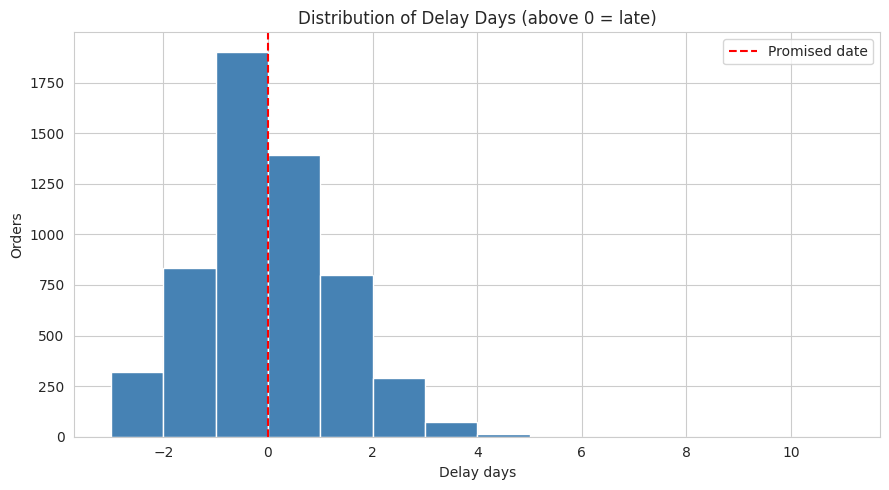

In [5]:
on_time_pct = delivered["OnTime"].mean() * 100
avg_delay_late = delivered[delivered["DelayDays"] > 0]["DelayDays"].mean()
avg_delivery_days = delivered["DeliveryDays"].mean()
failed_pct = (df["Status"] == "Failed").mean() * 100
returned_pct = (df["Status"] == "Returned").mean() * 100
late_count = (delivered["DelayDays"] > 0).sum()

print("On-time delivery rate:", round(on_time_pct, 1), "%")
print("Late deliveries:", late_count)
print("Average delay of late orders:", round(avg_delay_late, 2), "days")
print("Average delivery time:", round(avg_delivery_days, 2), "days")
print("Failed delivery rate:", round(failed_pct, 2), "%")
print("Returned rate:", round(returned_pct, 2), "%")

plt.figure(figsize=(9, 5))
plt.hist(delivered["DelayDays"], bins=range(-3, 12), color="steelblue", edgecolor="white")
plt.axvline(0, color="red", linestyle="--", label="Promised date")
plt.title("Distribution of Delay Days (above 0 = late)")
plt.xlabel("Delay days")
plt.ylabel("Orders")
plt.legend()
plt.tight_layout()
plt.savefig("delay_distribution.png", dpi=150)
plt.show()

## Step 5: Carrier performance

             orders  on_time_pct  avg_delay  avg_delivery_days  failed_pct
Carrier                                                                   
FastTrack      1708        91.22      -1.04               3.72        1.90
CityExpress    1414        83.45      -0.65               3.99        2.73
SafeShip       1401        78.23      -0.42               4.16        3.35
QuickMove      1120        56.79       0.28               4.95        5.26


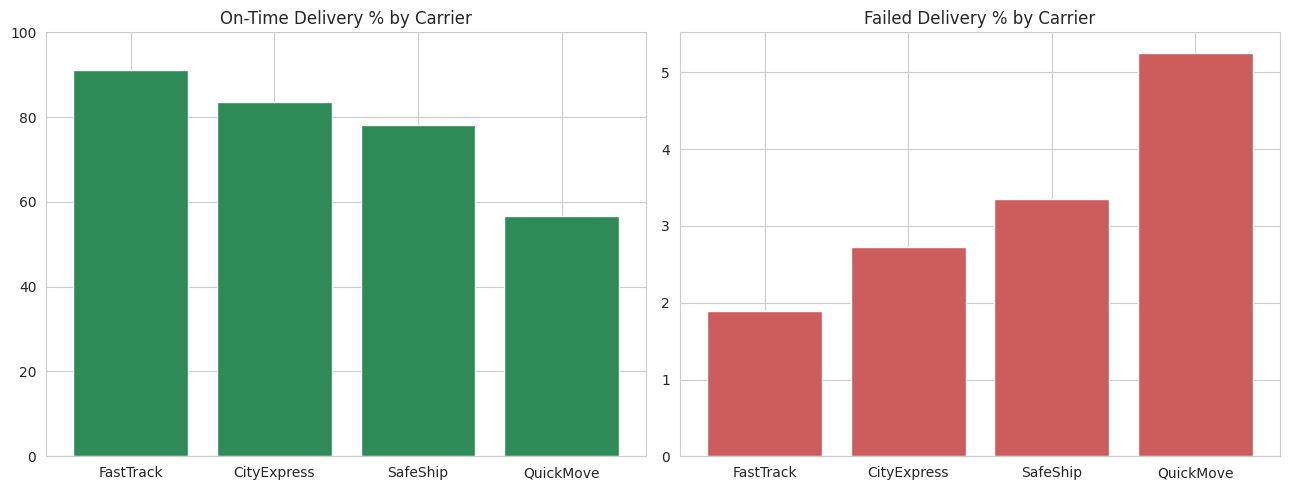

In [6]:
carrier_perf = delivered.groupby("Carrier").agg(
    orders=("OrderID", "count"),
    on_time_pct=("OnTime", lambda x: x.mean() * 100),
    avg_delay=("DelayDays", "mean"),
    avg_delivery_days=("DeliveryDays", "mean")
)
fail_by_carrier = df.groupby("Carrier")["Status"].apply(lambda x: (x == "Failed").mean() * 100)
carrier_perf["failed_pct"] = fail_by_carrier
carrier_perf = carrier_perf.sort_values("on_time_pct", ascending=False)
print(carrier_perf.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(carrier_perf.index, carrier_perf["on_time_pct"], color="seagreen")
axes[0].set_title("On-Time Delivery % by Carrier")
axes[0].set_ylim(0, 100)
axes[1].bar(carrier_perf.index, carrier_perf["failed_pct"], color="indianred")
axes[1].set_title("Failed Delivery % by Carrier")
plt.tight_layout()
plt.savefig("carrier_performance.png", dpi=150)
plt.show()

## Step 6: Region performance

         orders  on_time_pct  avg_delay
Region                                 
Central     869        86.42      -0.88
South      1394        85.29      -0.77
North      1103        80.78      -0.52
West       1416        79.59      -0.54
East        861        59.47       0.24


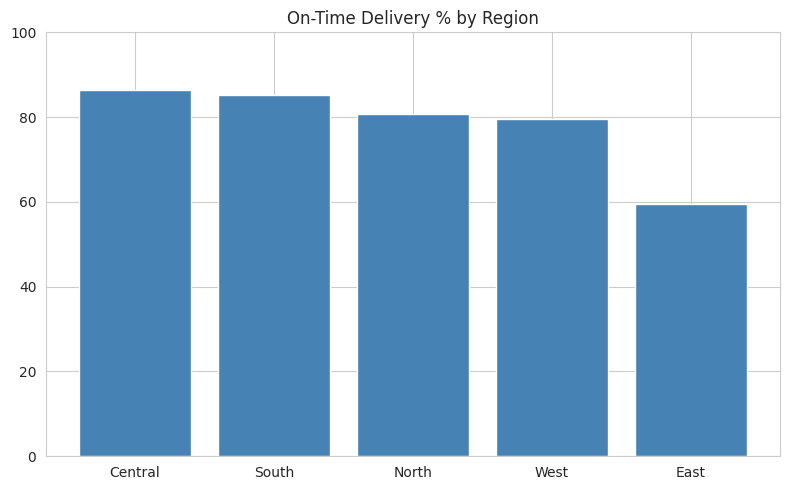

In [7]:
region_perf = delivered.groupby("Region").agg(
    orders=("OrderID", "count"),
    on_time_pct=("OnTime", lambda x: x.mean() * 100),
    avg_delay=("DelayDays", "mean")
).sort_values("on_time_pct", ascending=False)
print(region_perf.round(2))

plt.figure(figsize=(8, 5))
plt.bar(region_perf.index, region_perf["on_time_pct"], color="steelblue")
plt.title("On-Time Delivery % by Region")
plt.ylim(0, 100)
plt.tight_layout()
plt.savefig("region_performance.png", dpi=150)
plt.show()

## Step 7: Carrier x Region heatmap
Which carrier is weak in which region?

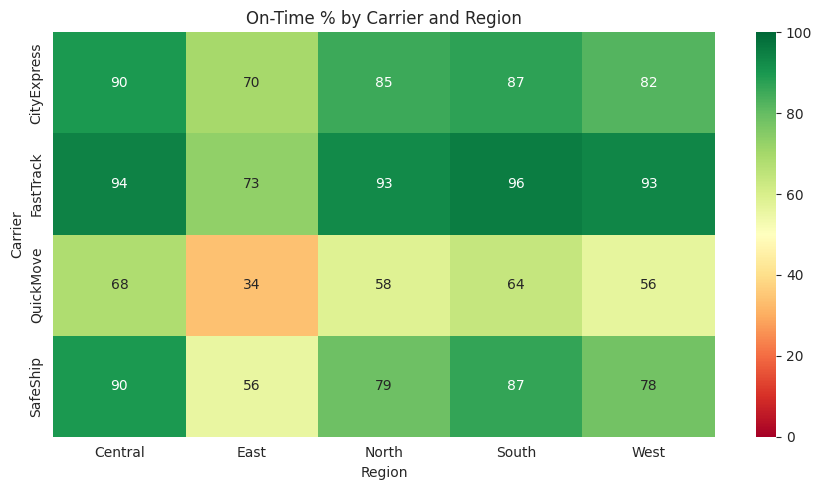

5 weakest carrier + region combinations (min 30 orders):
  Carrier Region  orders  on_time_pct
QuickMove   East     181         33.7
 SafeShip   East     227         55.5
QuickMove   West     279         56.3
QuickMove  North     212         58.5
QuickMove  South     266         63.9


In [8]:
combo = delivered.pivot_table(index="Carrier", columns="Region", values="OnTime", aggfunc="mean") * 100

plt.figure(figsize=(9, 5))
sns.heatmap(combo, annot=True, fmt=".0f", cmap="RdYlGn", vmin=0, vmax=100)
plt.title("On-Time % by Carrier and Region")
plt.tight_layout()
plt.savefig("carrier_region_heatmap.png", dpi=150)
plt.show()

combo_list = delivered.groupby(["Carrier", "Region"]).agg(orders=("OrderID", "count"), on_time_pct=("OnTime", lambda x: x.mean() * 100)).reset_index()
combo_list = combo_list[combo_list["orders"] >= 30]
worst_combos = combo_list.sort_values("on_time_pct").head(5)
print("5 weakest carrier + region combinations (min 30 orders):")
print(worst_combos.round(1).to_string(index=False))

## Step 8: What causes delays? (distance, weight, weekday, month)

In [9]:
band = delivered.groupby("DistanceBand").agg(orders=("OrderID", "count"), on_time_pct=("OnTime", lambda x: x.mean() * 100), avg_delay=("DelayDays", "mean"))
print("By distance band:")
print(band.round(2))

delivered["WeightBand"] = pd.cut(delivered["WeightKg"], bins=[0, 3, 8, 15, 100], labels=["Light (0-3kg)", "Medium (3-8kg)", "Heavy (8-15kg)", "Very heavy (15kg+)"])
wband = delivered.groupby("WeightBand").agg(orders=("OrderID", "count"), on_time_pct=("OnTime", lambda x: x.mean() * 100))
print()
print("By weight band:")
print(wband.round(2))

print()
print("Correlation with delay days:")
print("Distance vs delay:", round(delivered["DistanceKm"].corr(delivered["DelayDays"]), 3))
print("Weight vs delay  :", round(delivered["WeightKg"].corr(delivered["DelayDays"]), 3))

By distance band:
                    orders  on_time_pct  avg_delay
DistanceBand                                      
Short (<200km)         931        89.90      -0.59
Medium (200-600km)    1914        83.39      -0.82
Long (600km+)         2798        72.80      -0.31

By weight band:
                    orders  on_time_pct
WeightBand                             
Light (0-3kg)         1963        81.00
Medium (3-8kg)        2053        80.37
Heavy (8-15kg)        1135        76.92
Very heavy (15kg+)     492        72.56

Correlation with delay days:
Distance vs delay: 0.186
Weight vs delay  : 0.097


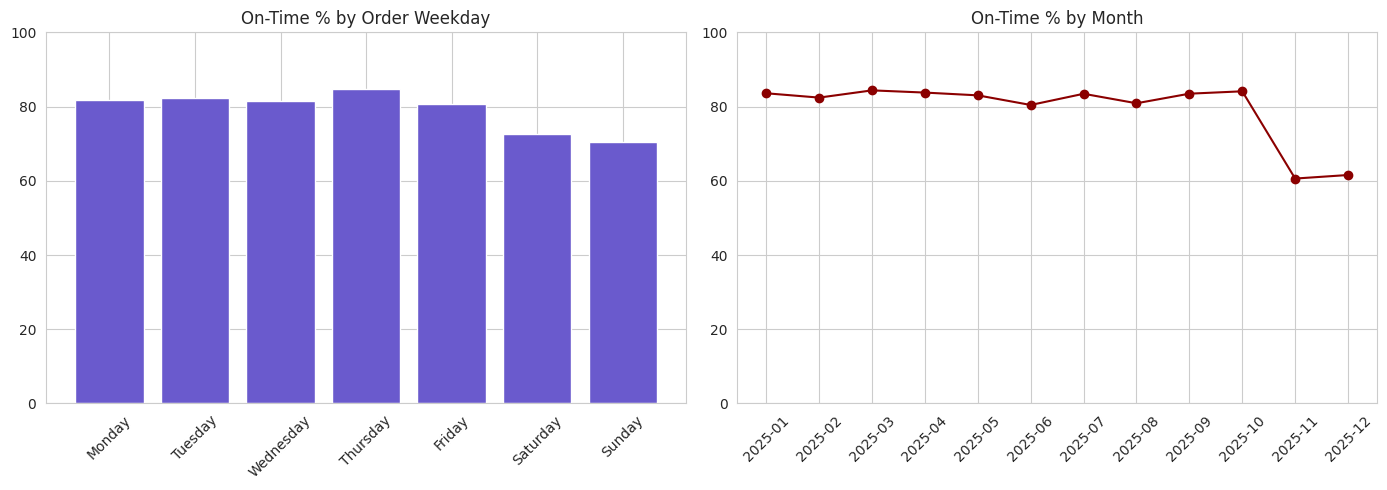

Weekday on-time %:
Weekday
Monday       81.9
Tuesday      82.4
Wednesday    81.6
Thursday     84.8
Friday       80.6
Saturday     72.5
Sunday       70.5
Name: OnTime, dtype: float64

Monthly on-time %:
OrderMonth
2025-01    83.6
2025-02    82.4
2025-03    84.4
2025-04    83.8
2025-05    83.0
2025-06    80.4
2025-07    83.4
2025-08    80.9
2025-09    83.5
2025-10    84.1
2025-11    60.6
2025-12    61.6
Freq: M, Name: OnTime, dtype: float64


In [10]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday_perf = delivered.groupby("Weekday")["OnTime"].mean().reindex(day_order) * 100
monthly_perf = delivered.groupby("OrderMonth")["OnTime"].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(weekday_perf.index, weekday_perf.values, color="slateblue")
axes[0].set_title("On-Time % by Order Weekday")
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_ylim(0, 100)
axes[1].plot(monthly_perf.index.astype(str), monthly_perf.values, marker="o", color="darkred")
axes[1].set_title("On-Time % by Month")
axes[1].tick_params(axis="x", rotation=45)
axes[1].set_ylim(0, 100)
plt.tight_layout()
plt.savefig("weekday_and_monthly_trend.png", dpi=150)
plt.show()

print("Weekday on-time %:")
print(weekday_perf.round(1))
print()
print("Monthly on-time %:")
print(monthly_perf.round(1))

## Step 9: Key insights (calculated from the output above)

In [11]:
best_carrier = carrier_perf.index[0]
worst_carrier = carrier_perf.index[-1]
best_region = region_perf.index[0]
worst_region = region_perf.index[-1]
worst_combo = worst_combos.iloc[0]
worst_month = monthly_perf.idxmin()
worst_day = weekday_perf.idxmin()
fail_worst_carrier = fail_by_carrier.idxmax()

print("KEY INSIGHTS")
print("-" * 50)
print("1. Overall on-time delivery rate is", round(on_time_pct, 1), "% and", round(failed_pct, 1), "% of orders failed")
print("2. Best carrier:", best_carrier, "(", round(carrier_perf.loc[best_carrier, "on_time_pct"], 1), "% on time )")
print("3. Weakest carrier:", worst_carrier, "(", round(carrier_perf.loc[worst_carrier, "on_time_pct"], 1), "% on time )")
print("4. Highest failed delivery rate:", fail_worst_carrier, "(", round(fail_by_carrier.max(), 1), "% )")
print("5. Weakest region:", worst_region, "(", round(region_perf.loc[worst_region, "on_time_pct"], 1), "% on time )")
print("6. Weakest carrier + region combo:", worst_combo["Carrier"], "in", worst_combo["Region"], "(", round(worst_combo["on_time_pct"], 1), "% on time )")
print("7. Long distance orders are on time", round(band.iloc[-1]["on_time_pct"], 1), "% vs", round(band.iloc[0]["on_time_pct"], 1), "% for short distance")
print("8. Worst month:", worst_month, "| Worst order weekday:", worst_day)
print()
print("RECOMMENDATIONS")
print("- Move volume from the weakest carrier to the best carrier in the weak regions")
print("- Give long distance orders a longer promised date so customers get realistic dates")
print("- Add extra delivery capacity before the worst month (festive / year end rush)")
print("- Review contract and penalty terms with the carrier that has the highest failed rate")

KEY INSIGHTS
--------------------------------------------------
1. Overall on-time delivery rate is 79.2 % and 3.2 % of orders failed
2. Best carrier: FastTrack ( 91.2 % on time )
3. Weakest carrier: QuickMove ( 56.8 % on time )
4. Highest failed delivery rate: QuickMove ( 5.3 % )
5. Weakest region: East ( 59.5 % on time )
6. Weakest carrier + region combo: QuickMove in East ( 33.7 % on time )
7. Long distance orders are on time 72.8 % vs 89.9 % for short distance
8. Worst month: 2025-11 | Worst order weekday: Sunday

RECOMMENDATIONS
- Move volume from the weakest carrier to the best carrier in the weak regions
- Give long distance orders a longer promised date so customers get realistic dates
- Add extra delivery capacity before the worst month (festive / year end rush)
- Review contract and penalty terms with the carrier that has the highest failed rate


In [12]:
carrier_perf.to_csv("carrier_performance.csv")
region_perf.to_csv("region_performance.csv")
worst_combos.to_csv("weakest_carrier_region_combos.csv", index=False)
df.to_csv("delivery_orders_clean.csv", index=False)
print("Saved files:", [f for f in os.listdir(".") if f.endswith(".png") or f.endswith(".csv")])

Saved files: ['weekday_and_monthly_trend.png', 'carrier_performance.csv', 'delay_distribution.png', 'carrier_region_heatmap.png', 'weakest_carrier_region_combos.csv', 'delivery_orders_clean.csv', 'region_performance.csv', 'carrier_performance.png', 'region_performance.png']


In [ ]:

# ============================================================
# UNIVERSAL COLAB PROJECT AUTO-SAVE
# Structure: Parent Folder / Notebook Name / All Project Files
# ============================================================

import os
import json
import shutil
from pathlib import Path
from google.colab import auth, _message
from googleapiclient.discovery import build
from googleapiclient.http import MediaFileUpload
from google.auth import default

# 1. DESTINATION GOOGLE DRIVE FOLDER
PARENT_FOLDER_ID = "1RJ_KbIui8TyupB2kr3c-N93lt2OE0nAk"

# 2. AUTHENTICATE
auth.authenticate_user()
credentials, _ = default()
drive = build("drive", "v3", credentials=credentials)

# 3. DETECT CURRENT NOTEBOOK
notebook_data = _message.blocking_request("get_ipynb")

if "ipynb" in notebook_data:
    notebook_data = notebook_data["ipynb"]

project_name = (
    notebook_data.get("metadata", {})
    .get("colab", {})
    .get("name", "")
)

if not project_name:
    project_name = input("Enter your Colab notebook name (e.g. RAG): ").strip()

project_name = Path(project_name).stem

if not project_name:
    raise ValueError("Project name is missing.")

print("Project detected:", project_name)

# 4. FIND OR CREATE PROJECT FOLDER
query = (
    f"'{PARENT_FOLDER_ID}' in parents "
    f"and name = '{project_name}' "
    "and mimeType = 'application/vnd.google-apps.folder' "
    "and trashed = false"
)

results = drive.files().list(
    q=query,
    fields="files(id,name)",
    supportsAllDrives=True,
    includeItemsFromAllDrives=True
).execute()

if results.get("files"):
    PROJECT_FOLDER_ID = results["files"][0]["id"]
else:
    folder = drive.files().create(
        body={
            "name": project_name,
            "mimeType": "application/vnd.google-apps.folder",
            "parents": [PARENT_FOLDER_ID]
        },
        fields="id"
    ).execute()

    PROJECT_FOLDER_ID = folder["id"]

# 5. UPLOAD FILES WITHOUT ZIP
SKIP_DIRS = {
    "drive", "sample_data", ".config",
    ".cache", "__pycache__"
}

uploaded = 0
failed = []

def find_existing_file(name, parent_id):
    q = (
        f"'{parent_id}' in parents "
        f"and name = '{name}' "
        "and trashed = false"
    )
    found = drive.files().list(
        q=q,
        fields="files(id)",
        supportsAllDrives=True,
        includeItemsFromAllDrives=True
    ).execute()
    return found.get("files", [])

def upload_file(local_path, parent_id):
    global uploaded

    filename = os.path.basename(local_path)

    metadata = {
        "name": filename,
        "parents": [parent_id]
    }

    media = MediaFileUpload(
        local_path,
        resumable=True
    )

    existing = find_existing_file(filename, parent_id)

    if existing:
        drive.files().update(
            fileId=existing[0]["id"],
            media_body=media,
            supportsAllDrives=True
        ).execute()
    else:
        drive.files().create(
            body=metadata,
            media_body=media,
            fields="id",
            supportsAllDrives=True
        ).execute()

    uploaded += 1
    print("Saved:", filename)

def upload_directory(local_dir, drive_parent_id):
    for item in os.scandir(local_dir):

        if item.is_dir(follow_symlinks=False):

            if item.name in SKIP_DIRS:
                continue

            existing = find_existing_file(
                item.name, drive_parent_id
            )

            if existing:
                subfolder_id = existing[0]["id"]
            else:
                result = drive.files().create(
                    body={
                        "name": item.name,
                        "mimeType": "application/vnd.google-apps.folder",
                        "parents": [drive_parent_id]
                    },
                    fields="id",
                    supportsAllDrives=True
                ).execute()
                subfolder_id = result["id"]

            upload_directory(item.path, subfolder_id)

        elif item.is_file(follow_symlinks=False):
            try:
                upload_file(item.path, drive_parent_id)
            except Exception as error:
                failed.append((item.name, str(error)))
                print("Upload failed:", item.name, error)

# 6. SAVE EXECUTED NOTEBOOK
notebook_path = f"/content/{project_name}.ipynb"

with open(notebook_path, "w", encoding="utf-8") as f:
    json.dump(notebook_data, f, ensure_ascii=False, indent=2)

# 7. UPLOAD PROJECT FILES
upload_directory("/content", PROJECT_FOLDER_ID)

# 8. FINAL REPORT
print("\n======================================")
print("PROJECT BACKUP COMPLETED")
print("======================================")
print("Project:", project_name)
print("Uploaded files:", uploaded)
print("Failed files:", len(failed))
print(
    "Folder:",
    f"https://drive.google.com/drive/folders/{PROJECT_FOLDER_ID}"
)

if failed:
    print("\nFailed uploads:")
    for name, error in failed:
        print(name, error)

---
*Built by Akshat Kesharwani | Portfolio: https://akshatkesharwani-info.github.io/ | GitHub: https://github.com/akshatkesharwani-info*